
# CS664 HW5 Part1 - Wei Zhao

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import numpy as np

In [11]:
# Replace the seed with the last four digits of your BU ID

seed = 6449
np.random.seed(seed)

n_samples = 1000
X = np.random.uniform(-25, 25, size=(n_samples, 1)).astype('float32')
y = X ** 2

In [12]:
X.shape, y.shape

((1000, 1), (1000, 1))

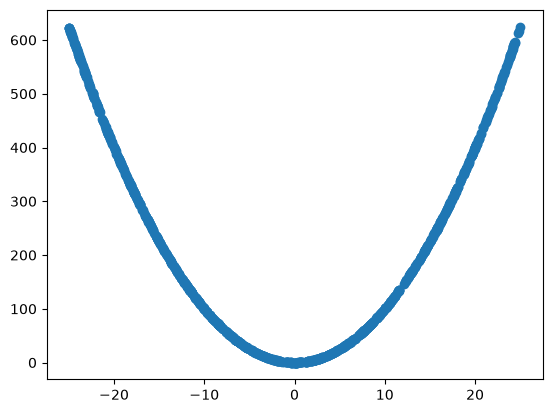

In [13]:
# Visualize with a plot

plt.scatter(x=X[:, 0], y=y[:, 0]);

In [14]:
# Convert NumPy arrays to PyTorch tensors

X_tensor = torch.FloatTensor(X)
y_tensor = torch.FloatTensor(y)

X_tensor.shape, y_tensor.shape

(torch.Size([1000, 1]), torch.Size([1000, 1]))

In [15]:
# Split data into train and test sets

X_train, X_test, y_train, y_test = train_test_split(
    X_tensor, y_tensor, test_size=0.2, random_state=seed )

In [16]:
# Define the Neural Network with non-linearity (ReLU)

class SquareModel(nn.Module):

  def __init__(self, hidden_features=8):
    super().__init__()
    # Fill in the code to define the layers of the neural network
    self.layer1 = nn.Linear(1, hidden_features)
    self.relu = nn.ReLU()
    self.layer2 = nn.Linear(hidden_features, 1)

  def forward(self, x):
    return self.layer2(self.relu(self.layer1(x)))

In [17]:
def test_model(hidden_features):
    torch.manual_seed(seed)
    model = SquareModel(hidden_features)

    # Setup Loss function and Optimizer

    loss_fn = nn.MSELoss()  
    optimizer = torch.optim.SGD(model.parameters(), lr=0.0001)
    
    # Training Loop
    
    epochs = 500000
    for epoch in range(epochs):
      # Forward pass (predictions)
      y_values = model(X_train)
    
      # Calculate loss
      loss = loss_fn(y_values, y_train)
      if epoch % 50000 == 0:
          print(f" Epoch {epoch:6d} Loss {loss:8.4f}")
    
      # Optimizer zero grad
      optimizer.zero_grad()
    
      # Backward pass (backpropagation)
      loss.backward()
    
      # Optimizer step (gradient descent)
      optimizer.step()
    
    # Evaluate the Model
    
    model.eval()
    with torch.inference_mode():
      test_outputs = model(X_test)
      loss = loss_fn(test_outputs, y_test)
    
    print(f"MSE Loss with test data: {loss:.4f}\n") 

    # Test the given inputs
    test_inputs = torch.tensor([[5.0],[-5.0], [7.0], [-7.0], [20.0], [-20.0], [50.0], [100.0]])
    model.eval()
    with torch.inference_mode():
        test_outputs = model(test_inputs)

    # Print the results
    for x,y in zip(test_inputs, test_outputs):
        print(f"Input = {x.item():6.0f} Actual Output = {(x**2).item():6.0f} Predicted Output = {y.item():6.2f}")
    
        

In [18]:
test_model(8)

 Epoch      0 Loss 76675.7578
 Epoch  50000 Loss  43.6467
 Epoch 100000 Loss  39.1915
 Epoch 150000 Loss 108.1301
 Epoch 200000 Loss  27.3888
 Epoch 250000 Loss  18.0631
 Epoch 300000 Loss  12.3629
 Epoch 350000 Loss  11.5684
 Epoch 400000 Loss  10.5643
 Epoch 450000 Loss  11.6520
MSE Loss with test data: 9.5997

Input =      5 Actual Output =     25 Predicted Output =  26.86
Input =     -5 Actual Output =     25 Predicted Output =  26.72
Input =      7 Actual Output =     49 Predicted Output =  45.99
Input =     -7 Actual Output =     49 Predicted Output =  52.59
Input =     20 Actual Output =    400 Predicted Output = 400.74
Input =    -20 Actual Output =    400 Predicted Output = 404.52
Input =     50 Actual Output =   2500 Predicted Output = 1726.30
Input =    100 Actual Output =  10000 Predicted Output = 3935.56


In [19]:
test_model(16)

 Epoch      0 Loss 81321.8594
 Epoch  50000 Loss  47.6536
 Epoch 100000 Loss  17.3347
 Epoch 150000 Loss  11.6195
 Epoch 200000 Loss  10.5873
 Epoch 250000 Loss   5.8171
 Epoch 300000 Loss   5.2234
 Epoch 350000 Loss   4.5823
 Epoch 400000 Loss   4.3312
 Epoch 450000 Loss   5.1050
MSE Loss with test data: 3.5207

Input =      5 Actual Output =     25 Predicted Output =  25.16
Input =     -5 Actual Output =     25 Predicted Output =  23.19
Input =      7 Actual Output =     49 Predicted Output =  49.44
Input =     -7 Actual Output =     49 Predicted Output =  51.20
Input =     20 Actual Output =    400 Predicted Output = 398.85
Input =    -20 Actual Output =    400 Predicted Output = 398.04
Input =     50 Actual Output =   2500 Predicted Output = 1751.64
Input =    100 Actual Output =  10000 Predicted Output = 4018.00
